# Bounded honest drift: frozen pilot companion
## tl;dr
The baseline is valid under its stated model but loses weak-attack sensitivity.
For plan 9 at the **1% expected exactly-known retained raw-bit floor**, the balanced
floor probe triggers Clopper–Pearson in **31/512, 2/512, 1/512, 1/512** trials
as the equal per-basis allowance grows through 0, 0.2425, 0.485 and 0.60625
QBER percentage points. These are four fixed probes, not continuous worst-case power.

All Hoeffding pilot decisions and all 24 lower-power endpoints are zero.
Across tested honest cohorts, CP has 0–2 alarms per 512 pairs; zero observed
alarms does not mean zero true false-alarm probability. At/above the overlap
boundary, no uniformly valid detector can have worst-case power exceeding alpha.
Publication novelty and final-key security are **not** established.

## Context & Methods
Read [the frozen protocol](../docs/drift-pilot-protocol.md),
[the model/proof](../docs/bounded-drift-model.md) and
[the later classical baseline audit](../docs/classical-baseline-audit.md).
**Why:** distinguish an attack from ordinary allowed between-block error drift,
not merely separate simulator labels. The two rules see the same public counts.
Their alpha=5% upper false-alarm guarantees are equal, not their attained FPRs.

### Key Assumptions
Independent, blockwise iid trusted attack-free calibration and monitoring;
constant per-basis probabilities in each block, shared by both preparation bits;
stable gains; error-independent selection; authenticated disclosure; a predeclared
error envelope. The attack branch keeps lambda=0.03 fixed and uses iid
intercept-resend. Concurrent attack/noise drift, gain drift and repeated peeking
are outside this model. Calibration authenticity does not prove it is attack-free.

For floor kappa, d_star=(1-lambda)*kappa/2. With positive error-observation
resources in both stages, d_Z+d_X >= (1-lambda)*kappa permits exact population-law
overlap. The r/2 raw-bit proxy is neither mutual information nor final secret-key leakage.
Emission/sacrifice matching is not equal hardware cost or secure-key yield.

Setup: `python -m pip install -r requirements.txt`.
Run `python quantum-ai-lab/scripts/build_drift_notebook.py` using the same
environment as the frozen runner. Rerunning this notebook reads evidence and
recreates figures; it does not rerun, filter or retune the pilot.

### 1. Setup

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

candidates = [Path.cwd(), Path.cwd()/'quantum-ai-lab', Path.cwd().parent]
root = next(p for p in candidates if (p/'src/research/drift_detector.py').is_file())
evidence = root/'results/benchmarks/drift-pilot-v1'
figures = root/'docs/figures/drift-pilot-v1'
figures.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 120})
colors = {'clopper-pearson': '#245b87', 'hoeffding': '#786c48'}
def show(fig, filename, alt):
    fig.savefig(figures/filename, dpi=150, bbox_inches='tight')
    display(Image(filename=str(figures/filename), alt=alt))
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


## Data
### 2. Verify frozen inputs
Source: `results/benchmarks/drift-pilot-v1/pilot.json`, `public_counts.csv.gz`
and `audit.json`. There are 216 cohorts × 512 public pairs; every pair is retained.
The audit replays all decisions, regenerates every count from the saved seeds,
and scalar-checks fixed first/middle/last rows. CP references share SciPy;
this is not an independent library, floating-rounding or hardware certificate.

In [2]:
result = json.loads((evidence/'pilot.json').read_text())
audit = json.loads((evidence/'audit.json').read_text())
for relative, expected in result['source_sha256'].items():
    assert hashlib.sha256((root/relative).read_bytes()).hexdigest() == expected
for filename, expected in result['output_sha256'].items():
    assert hashlib.sha256((evidence/filename).read_bytes()).hexdigest() == expected
assert audit['status'] == 'passed' and result['public_pairs'] == 110592
assert result['protocol']['trials'] == 512 and len(result['cells']) == 432
keys = ('plan_id', 'floor_id', 'allowance_id', 'cohort_id', 'method')
cells = {tuple(c[k] for k in keys): c for c in result['cells']}
assert len(cells) == 432
print('Public pairs:', result['public_pairs'], ' | Decision replays:', audit['decision_replays'])
print('Frozen environment:', result['versions'])
print('Joint uncertainty: 4% failure for 432 rates + 1% for 24 mean lower bounds.')

Public pairs: 110592  | Decision replays: 221184
Frozen environment: {'python': '3.12.14', 'numpy': '2.5.3', 'scipy': '1.18.1'}
Joint uncertainty: 4% failure for 432 rates + 1% for 24 mean lower bounds.


### 3. Reconcile expected and observed resources
Four million emitted pulses per pair; C=2 million effective test emissions
fixes expected total sacrifice and remaining candidates. Printed observations
use one independently drawn stable cohort per plan, not a pooled or selected rate.
These are sifted raw candidates before error correction and privacy amplification.

In [3]:
for plan in result['protocol']['plans']:
    c = cells[(plan['id'], 1, 0, 0, 'clopper-pearson')]
    observed = c['mean_calibration_sacrificed']+c['mean_monitoring_disclosed']
    print(f"Plan {plan['id']}: M={plan['calibration_emitted']:,}, f={plan['monitoring_disclosure']:.6f}")
    print(f"  expected sacrifice={plan['total_sacrificed']:.2f}; observed mean={observed:.2f}")
    print(f"  expected candidates={plan['remaining_candidates']:.2f}; observed mean={c['mean_remaining_candidates']:.2f}")
assert np.isclose(result['protocol']['plans'][0]['total_sacrificed'],
                  result['protocol']['plans'][1]['total_sacrificed'])

Plan 9: M=800,000, f=0.375000
  expected sacrifice=43572.29; observed mean=43572.52
  expected candidates=43572.29; observed mean=43572.44
Plan 10: M=1,333,333, f=0.250000
  expected sacrifice=43572.29; observed mean=43580.08
  expected candidates=43572.29; observed mean=43560.75


## Results
### 4. Balanced floor probes: all declared floors and allocations
Error bars are the saved joint intervals, constructed with per-rate failure
0.04/432. Across all 432 rates and 24 mean bounds the joint coverage is at least
95% in real arithmetic. These intervals describe Monte Carlo rate uncertainty,
not device variation. Connecting the four predeclared settings is a visual guide,
not interpolation of untested allowances. Each point has denominator 512.

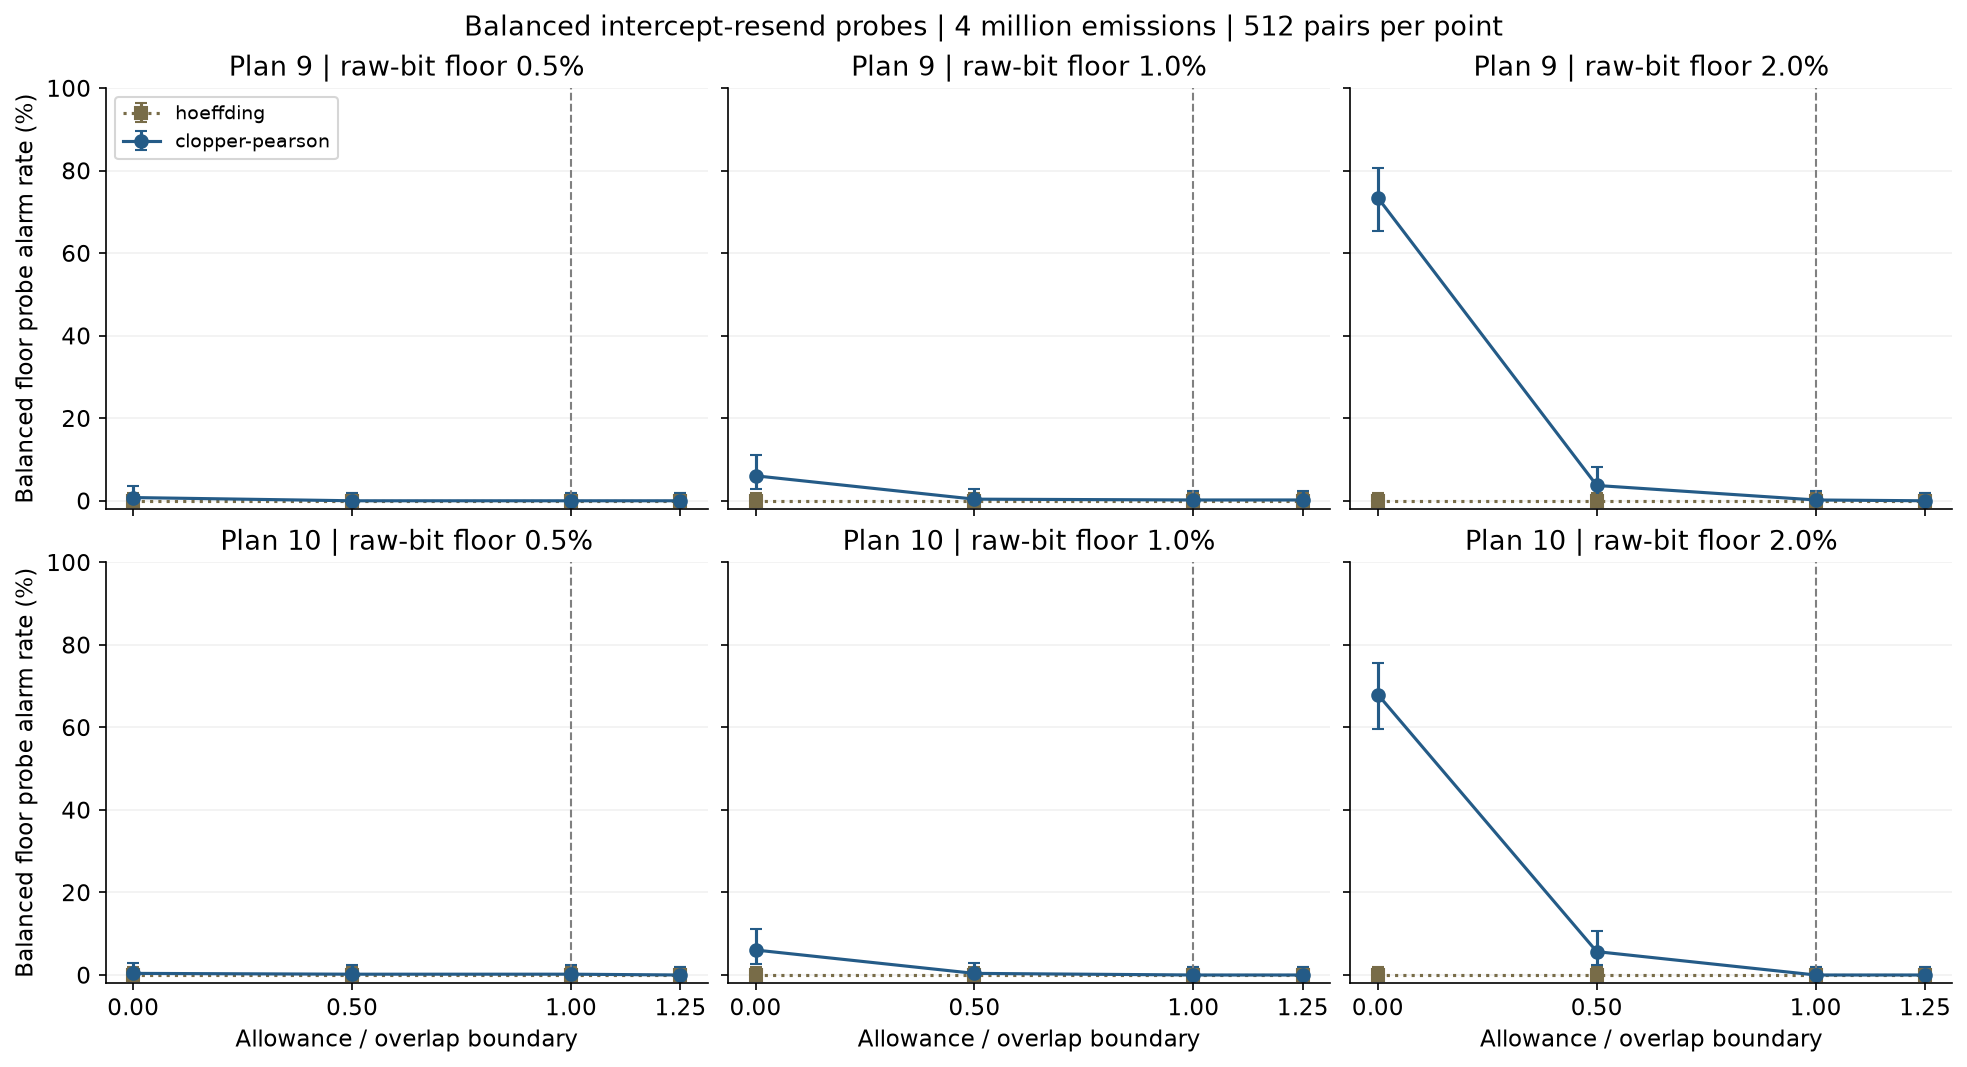

In [4]:
multipliers = np.array(result['protocol']['drift_multipliers'])
def series(ax, plan, floor_id, cohort, method, label=None):
    selected = [cells[(plan, floor_id, a, cohort, method)] for a in range(4)]
    y = np.array([c['alarm_rate']*100 for c in selected])
    low = np.array([c['ci_joint95'][0]*100 for c in selected])
    high = np.array([c['ci_joint95'][1]*100 for c in selected])
    ax.errorbar(multipliers, y, yerr=np.vstack([y-low, high-y]),
                color=colors[method], marker='o' if method=='clopper-pearson' else 's',
                linestyle='-' if method=='clopper-pearson' else ':',
                capsize=3, label=label or method)
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True, sharey=True,
                         layout='constrained')
for row, plan in enumerate((9, 10)):
    for fi, floor in enumerate(result['protocol']['floors']):
        ax = axes[row, fi]
        for method in result['protocol']['methods']:
            series(ax, plan, fi, 7, method)
        ax.axvline(1, color='0.5', linewidth=1, linestyle='--')
        ax.set_title(f'Plan {plan} | raw-bit floor {floor:.1%}')
        ax.set_ylim(-2, 100); ax.set_xticks(multipliers)
        ax.grid(axis='y', alpha=.18)
        if row == 1: ax.set_xlabel('Allowance / overlap boundary')
        if fi == 0: ax.set_ylabel('Balanced floor probe alarm rate (%)')
axes[0, 0].legend(fontsize=9)
fig.suptitle('Balanced intercept-resend probes | 4 million emissions | 512 pairs per point')
show(fig, 'balanced-probes.png',
     'Six panels compare balanced floor-probe alarm rates for both allocations and all three floors. CP detection falls with allowed drift; Hoeffding is zero. Joint intervals are shown.')

Balanced 2% floor probes can have high CP detection at zero allowed drift
(376/512 and 348/512); this collapses to 19/512 and 29/512 at half the boundary.
At/above the boundary the balanced floor attack is itself an allowed honest law,
so family-wide sensitivity cannot be rescued merely by more samples.

### 5. Honest controls versus the 5% target
This focused view uses the stable and both-upper-edge honest cohorts at the 1%
floor for both plans. The five honest controls per setting remain in the saved
evidence. Zero transmission is retained, not filtered as an unsuccessful run.

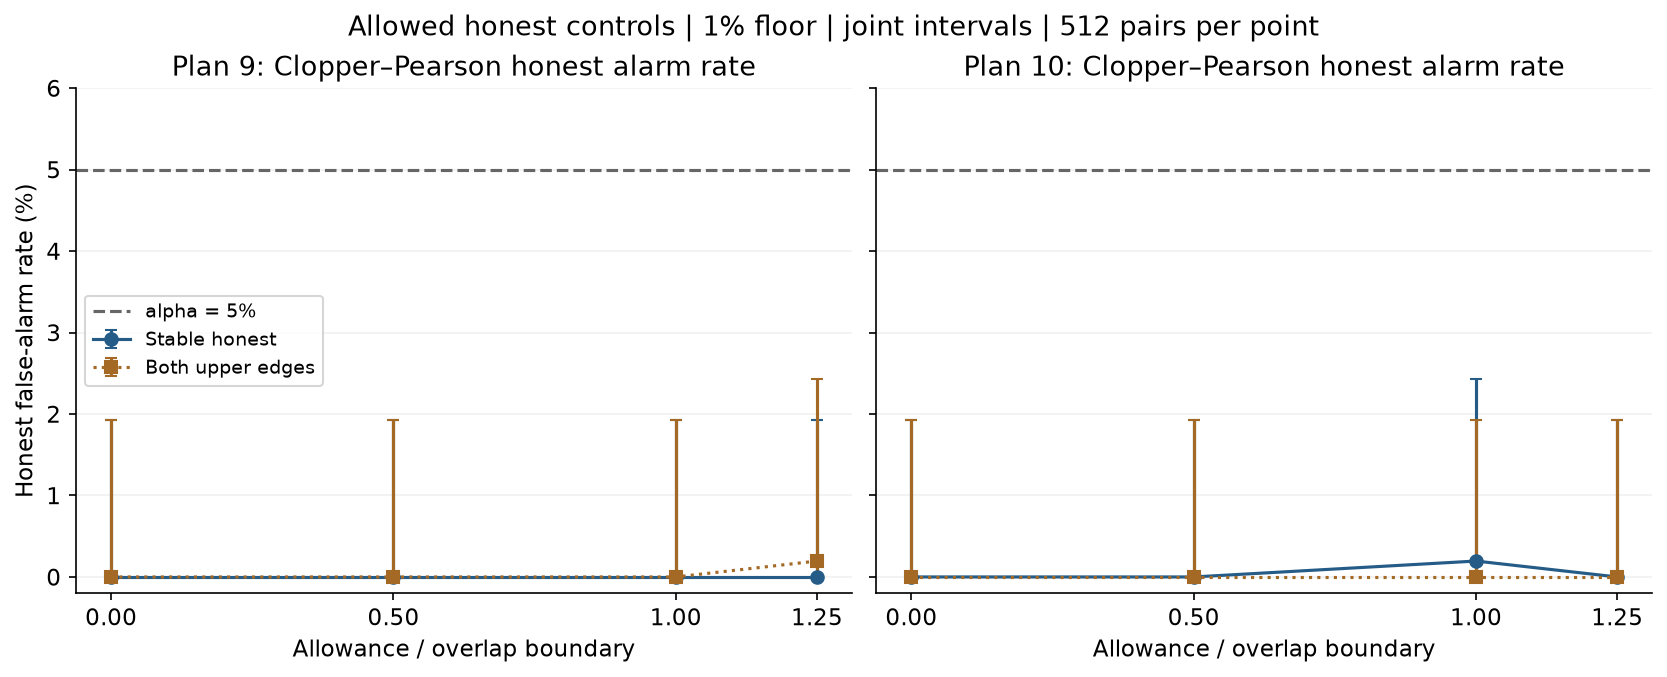

hoeffding honest alarms range: 0 to 0 of 512 per cohort
largest saved joint upper endpoint: 1.9304%
clopper-pearson honest alarms range: 0 to 2 of 512 per cohort
largest saved joint upper endpoint: 2.8572%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True, layout='constrained')
for ax, plan in zip(axes, (9, 10)):
    for cohort, label in ((0, 'Stable honest'), (1, 'Both upper edges')):
        selected = [cells[(plan, 1, a, cohort, 'clopper-pearson')] for a in range(4)]
        y = np.array([c['alarm_rate']*100 for c in selected])
        lo = np.array([c['ci_joint95'][0]*100 for c in selected])
        hi = np.array([c['ci_joint95'][1]*100 for c in selected])
        ax.errorbar(multipliers, y, yerr=[y-lo, hi-y], capsize=3,
                    marker='o' if cohort==0 else 's', linestyle='-' if cohort==0 else ':',
                    color='#245b87' if cohort==0 else '#a56926', label=label)
    ax.axhline(5, color='0.4', linestyle='--', label='alpha = 5%')
    ax.set_title(f'Plan {plan}: Clopper–Pearson honest alarm rate')
    ax.set_xlabel('Allowance / overlap boundary'); ax.set_xticks(multipliers)
    ax.set_ylim(-.2, 6); ax.grid(axis='y', alpha=.18)
axes[0].set_ylabel('Honest false-alarm rate (%)'); axes[0].legend(fontsize=9)
fig.suptitle('Allowed honest controls | 1% floor | joint intervals | 512 pairs per point')
show(fig, 'honest-controls.png',
     'Stable and upper-edge honest controls for both plans at the 1% floor. CP rates are low with joint intervals below the 5% reference in this selected view.')
for method in result['protocol']['methods']:
    honest = [c for c in result['cells'] if c['cohort_id']<5 and c['method']==method]
    print(method, 'honest alarms range:', min(c['alarms'] for c in honest),
          'to', max(c['alarms'] for c in honest), 'of 512 per cohort')
    print('largest saved joint upper endpoint:', f"{max(c['ci_joint95'][1] for c in honest):.4%}")

Low observed false alarms are compatible with a conservative rule, not evidence
that the entire honest family has been empirically checked. The proof, rather
than these five controls, supplies model-wide size control. Combining both rules
with OR would require a separate budget/proof; this experiment does not do that.

### 6. Stronger attack contrast and exact-value lookup
Plan 9, 1% floor: CP rates and saved joint interval endpoints, in percent.
The higher-rate balanced probe has r=0.04 and a 2% raw-bit proxy; it is not
evidence that every attack meeting the 1% floor is detected this well.

In [6]:
for a, mult in enumerate(multipliers):
    print(f'Equal per-basis allowance: {.485*mult:.5f} QBER percentage points')
    for cohort, label in ((7, 'Floor balanced'), (8, 'Double-rate balanced')):
        c = cells[(9, 1, a, cohort, 'clopper-pearson')]
        print(f"  {label}: {c['alarms']}/512, {c['alarm_rate']:.2%}, joint [{100*c['ci_joint95'][0]:.6g}, {100*c['ci_joint95'][1]:.6g}]%")
assert sum(c['alarms'] for c in result['cells'] if c['method']=='hoeffding') == 0
assert all(m['mean_conditional_lower']==0 and m['unconditional_power_lower_joint95']==0
           for m in result['mean_bounds'])
print('All 24 Hoeffding sample mean lower functions and joint endpoints: zero.')

Equal per-basis allowance: 0.00000 QBER percentage points
  Floor balanced: 31/512, 6.05%, joint [2.73883, 11.2104]%
  Double-rate balanced: 392/512, 76.56%, joint [68.6449, 83.379]%
Equal per-basis allowance: 0.24250 QBER percentage points
  Floor balanced: 2/512, 0.39%, joint [0.00188728, 2.85722]%
  Double-rate balanced: 157/512, 30.66%, joint [23.0602, 39.0685]%
Equal per-basis allowance: 0.48500 QBER percentage points
  Floor balanced: 1/512, 0.20%, joint [9.04245e-06, 2.4313]%
  Double-rate balanced: 27/512, 5.27%, joint [2.2266, 10.1953]%
Equal per-basis allowance: 0.60625 QBER percentage points
  Floor balanced: 1/512, 0.20%, joint [9.04245e-06, 2.4313]%
  Double-rate balanced: 11/512, 2.15%, joint [0.476177, 5.84316]%
All 24 Hoeffding sample mean lower functions and joint endpoints: zero.


## Takeaways
1. Baseline implementation and replay integrity passed; weak-attack sensitivity
   at this budget is inadequate, even outside population overlap.
2. Separately estimating calibration and monitoring probabilities and spending
   coverage across twelve intervals is conservative. CP exploits binomial
   variance and is tighter here than Hoeffding, but its weak floor power is low.
3. The zero Hoeffding bound means the current bound is uninformative, **not** that
   every optimal detector has zero power. At/above overlap, the separate
   indistinguishability theorem is the relevant obstruction.
4. No allocation winner, global Eve best response, hardware feasibility,
   new physics, final-key security or publication priority is demonstrated.
5. Next proposed milestone (requires confirmation): design a direct bounded-drift
   two-sample test with nuisance-uniform false-alarm control, then freeze and
   compare at the same budgets. Do not reuse this pilot for tuning and final evaluation.

Sources: frozen protocol and `pilot.json`, public archive and `audit.json` listed
above. Full narrative: [drift-pilot.md](../docs/drift-pilot.md).